# Лабораторна робота 3
Класифікатор k найближчих сусідів, k-NN

Тема: вибір параметра k, метрики відстані, зважений k-NN та вплив прокляття розмірності

**Проєкт команди:** *Банківський скролинг* — прогноз відтоку клієнтів банку (Churn Modelling)
**Склад команди:** *Сотниченко Артем*;
 *Вірченко Богдан*; 
 *Микитиа Тринько*;
**Група:** *[КН23002б]*

Мета роботи: побудувати метричний класифікатор k-NN на підготовлених у лабораторній 2 даних, дослідити вплив k і метрики відстані, спробувати зважений варіант та подивитись як кількість ознак впливає на якість і швидкість передбачення.

## 1. Підготовка середовища і даних

Беремо вже підготовлені дані з лабораторної 2 А саме train і test файли, які зберіг попередній нотбук тому поділ на вибірки лишається тим самим 

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print("train:", X_train.shape, "test:", X_test.shape)
print("ознаки:", list(X_train.columns))
print("частка класу 1 у train: %.3f, у test: %.3f" % (y_train.mean(), y_test.mean()))
print("пропусків:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

majority_acc = max(y_test.mean(), 1 - y_test.mean())
print("accuracy якщо завжди казати клас 0: %.4f" % majority_acc)

# перевіряємо що числові ознаки справді стандартизовані, середнє близько 0 а std близько 1
display(X_train.describe().loc[["mean", "std"]].round(3))

train: (8000, 9) test: (2000, 9)
ознаки: ['CreditScore', 'Gender', 'Age', 'Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']
частка класу 1 у train: 0.204, у test: 0.203
пропусків: 0
accuracy якщо завжди казати клас 0: 0.7965


,CreditScore,Gender,Age,Balance,NumOfProducts,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
mean,-0.0,0.548,-0.0,-0.0,-0.0,0.515,-0.0,0.239,0.237
std,1.0,0.498,1.0,1.0,1.0,0.500,1.0,0.426,0.426


In [3]:
# допоміжні функції щоб не повторювати код
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

def time_predict(model, X, repeats=3):
    # беремо найкращий час із кількох запусків щоб менше впливали випадкові затримки
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(X)
        times.append(time.perf_counter() - start)
    return min(times)

## Частина 1. Базовий k-NN

Навчаємо KNeighborsClassifier з k = 5 і евклідовою метрикою як вимагає завдання. Рахуємо accuracy, precision, recall, F1 і будуємо матрицю помилок. Класи в нас незбалансовані, тому дивитись тільки на accuracy не можна а головне це recall і F1 для клієнтів які пішли

In [4]:
knn_base = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn_base.fit(X_train, y_train)
y_pred_base = knn_base.predict(X_test)

m_base = get_metrics(y_test, y_pred_base)
display(pd.DataFrame(m_base, index=["k=5 euclidean"]).round(4))

print(classification_report(y_test, y_pred_base,
                            target_names=["залишився 0", "пішов 1"], zero_division=0))

,Accuracy,Precision,Recall,F1
k=5 euclidean,0.844,0.6792,0.4423,0.5357


              precision    recall  f1-score   support

 залишився 0       0.87      0.95      0.91      1593
     пішов 1       0.68      0.44      0.54       407

    accuracy                           0.84      2000
   macro avg       0.77      0.69      0.72      2000
weighted avg       0.83      0.84      0.83      2000



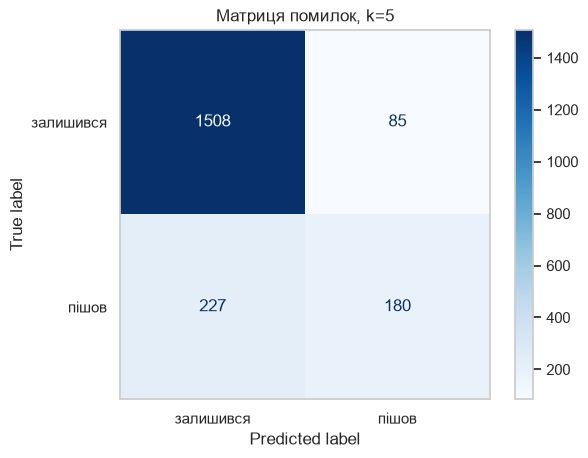

правильно знайдено тих хто пішов: 180, пропущено: 227, хибних тривог: 85


In [5]:
cm = confusion_matrix(y_test, y_pred_base)
ConfusionMatrixDisplay(cm, display_labels=["залишився", "пішов"]).plot(cmap="Blues")
plt.title("Матриця помилок, k=5")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"правильно знайдено тих хто пішов: {tp}, пропущено: {fn}, хибних тривог: {fp}")

## Частина 2. Вибір параметра k

Для непарних k від 1 до 25 рахуємо середню якість пятиблочної кросвалідації на train. Тестову вибірку для вибору k не використовуємоа для кожного k рахуємо accuracy і F1, а ще accuracy на самому train, шоб було видно перенавчання. Є нюанс у тому, що скейлер у лабораторній 2 вчився на всьому train тому в крос-валідації є невеликий вплив, але він мінімальний

Через дисбаланс класів accuracy в крос-валідації буде тягнути до великих k, бо там модель частіше голосує за більший кластомуобираємо за F1

In [6]:
ks = list(range(1, 26, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_acc = cross_val_score(knn, X_train, y_train, cv=cv, scoring="accuracy").mean()
    cv_f1 = cross_val_score(knn, X_train, y_train, cv=cv, scoring="f1").mean()
    train_acc = knn.fit(X_train, y_train).score(X_train, y_train)
    rows.append({"k": k, "train_acc": train_acc, "cv_acc": cv_acc, "cv_f1": cv_f1})

k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(4))

best_k = int(k_table["cv_f1"].idxmax())
best_k_acc = int(k_table["cv_acc"].idxmax())
print("найкраще k за F1:", best_k)
print("найкраще k за accuracy:", best_k_acc)

,train_acc,cv_acc,cv_f1
k,,,
1,1.0000,0.7920,0.4826
3,0.8994,0.8291,0.5235
5,0.8799,0.8390,0.5372
7,0.8716,0.8435,0.5341
9,0.8712,0.8462,0.5304
11,0.8674,0.8488,0.5316
13,0.8648,0.8491,0.5307
15,0.8625,0.8497,0.5244
17,0.8614,0.8496,0.5223


найкраще k за F1: 5
найкраще k за accuracy: 21


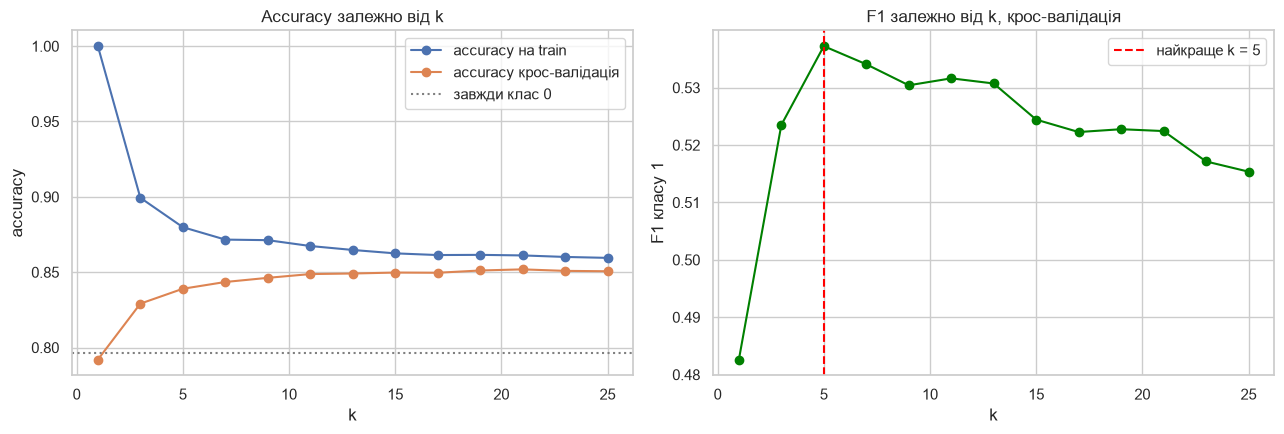

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(k_table.index, k_table["train_acc"], marker="o", label="accuracy на train")
ax[0].plot(k_table.index, k_table["cv_acc"], marker="o", label="accuracy крос-валідація")
ax[0].axhline(majority_acc, color="gray", ls=":", label="завжди клас 0")
ax[0].set_xlabel("k")
ax[0].set_ylabel("accuracy")
ax[0].set_title("Accuracy залежно від k")
ax[0].legend()

ax[1].plot(k_table.index, k_table["cv_f1"], marker="o", color="green")
ax[1].axvline(best_k, color="red", ls="--", label=f"найкраще k = {best_k}")
ax[1].set_xlabel("k")
ax[1].set_ylabel("F1 класу 1")
ax[1].set_title("F1 залежно від k, крос-валідація")
ax[1].legend()

plt.tight_layout()
plt.show()

In [8]:
# порівнюємо базове k=5 і обране k на тестовій вибірці
knn_best = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean").fit(X_train, y_train)
m_best = get_metrics(y_test, knn_best.predict(X_test))

cmp_k = pd.DataFrame({f"k=5 базове": m_base, f"k={best_k} обране": m_best}).T
display(cmp_k.round(4))

gap_k1 = k_table.loc[1, "train_acc"] - k_table.loc[1, "cv_acc"]
print(f"при k=1 accuracy на train {k_table.loc[1, 'train_acc']:.4f}, у крос-валідації {k_table.loc[1, 'cv_acc']:.4f}, різниця {gap_k1:.4f}")

,Accuracy,Precision,Recall,F1
k=5 базове,0.844,0.6792,0.4423,0.5357
k=5 обране,0.844,0.6792,0.4423,0.5357


при k=1 accuracy на train 1.0000, у крос-валідації 0.7920, різниця 0.2080


Як читати графіки-Зліва при k = 1 accuracy на train найвища, бо кожна точка сама собі найближчий сусід, а в кросвлідації якість нижча. Така різниця між train і кросвалідацією є ознака перенавчання зі зростанням k лінія train падає, а лінія кросвалідації підходить до рівня тривіального класифікатора, це вже  є недонавчання, де модель голосує за клас 0. Справа видно де F1 для клієнтів що пішли найвищий, цей максимум  є розумним компромісом

## Частина 3. Метрики відстані і зважений k-NN

При обраному k порівнюємо три метрики: евклідову, манхеттенську і Мінковського з p = 3. Для кожної пробуємо два варіанти голосування де uniform це класичне голосування більшості, distance це зважений k-NN, де голос сусіда дорівнює одиниці поділеній на відстань

In [9]:
metric_variants = [
    ("euclidean", dict(metric="euclidean")),
    ("manhattan", dict(metric="manhattan")),
    ("minkowski p=3", dict(metric="minkowski", p=3)),
]

grid_rows = []
for name, params in metric_variants:
    for w in ["uniform", "distance"]:
        model = KNeighborsClassifier(n_neighbors=best_k, weights=w, **params).fit(X_train, y_train)
        m = get_metrics(y_test, model.predict(X_test))
        grid_rows.append({"metric": name, "weights": w, **m})

grid = pd.DataFrame(grid_rows)
display(grid.round(4))

print("F1 по метриках і вагах")
display(grid.pivot(index="metric", columns="weights", values="F1").round(4))

,metric,weights,Accuracy,Precision,Recall,F1
0,euclidean,uniform,0.8440,0.6792,0.4423,0.5357
1,euclidean,distance,0.8405,0.6630,0.4398,0.5288
2,manhattan,uniform,0.8370,0.6441,0.4447,0.5262
3,manhattan,distance,0.8330,0.6246,0.4496,0.5229
4,minkowski p=3,uniform,0.8435,0.6741,0.4472,0.5377
5,minkowski p=3,distance,0.8430,0.6703,0.4496,0.5382


F1 по метриках і вагах


weights,distance,uniform
metric,,
euclidean,0.5288,0.5357
manhattan,0.5229,0.5262
minkowski p=3,0.5382,0.5377


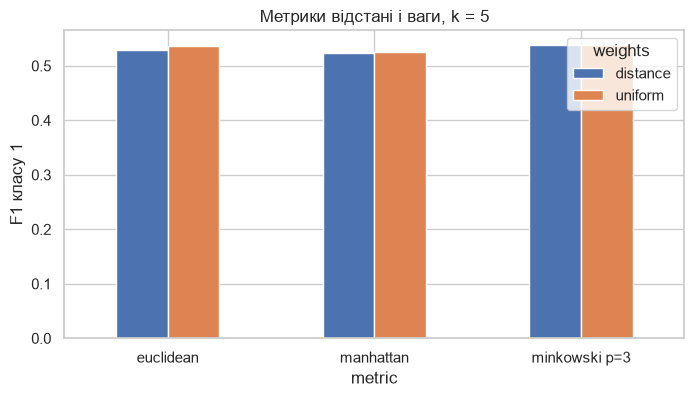

In [10]:
pivot_f1 = grid.pivot(index="metric", columns="weights", values="F1")
pivot_f1.plot(kind="bar", figsize=(8, 4))
plt.ylabel("F1 класу 1")
plt.title(f"Метрики відстані і ваги, k = {best_k}")
plt.xticks(rotation=0)
plt.show()

## Частина 4. Прокляття розмірності і швидкодія

Спочатку порівнюємо повний набір підготовлених ознак з трьома найінформативнішими. Інформативність міряємо кореляцією з цільовою змінною, рахуємо її тільки на train. Для порівняння беремо k, обране у частині 2, евклідову метрику і голосування uniform

In [11]:
corr_target = pd.concat([X_train, y_train], axis=1).corr()[TARGET].drop(TARGET)
ranking = corr_target.abs().sort_values(ascending=False)
display(ranking.round(3).to_frame("модуль кореляції з Exited"))

top3 = ranking.index[:3].tolist()
print("три найінформативніші ознаки:", top3)

,модуль кореляції з Exited
Age,0.309
Geography_Germany,0.174
IsActiveMember,0.152
Balance,0.121
Gender,0.106
Geography_Spain,0.057
NumOfProducts,0.054
CreditScore,0.033
EstimatedSalary,0.020


три найінформативніші ознаки: ['Age', 'Geography_Germany', 'IsActiveMember']


In [12]:
def eval_set(Xtr, Xte, k):
    model = KNeighborsClassifier(n_neighbors=k, metric="euclidean").fit(Xtr, y_train)
    t = time_predict(model, Xte)
    m = get_metrics(y_test, model.predict(Xte))
    m["n_features"] = Xtr.shape[1]
    m["predict_time_s"] = t
    return m

feat_cmp = pd.DataFrame({
    "три найкращі ознаки": eval_set(X_train[top3], X_test[top3], best_k),
    "усі підготовлені ознаки": eval_set(X_train, X_test, best_k),
}).T
display(feat_cmp.round(5))

,Accuracy,Precision,Recall,F1,n_features,predict_time_s
три найкращі ознаки,0.795,0.49345,0.27764,0.35535,3.0,0.01315
усі підготовлені ознаки,0.844,0.67925,0.44226,0.53571,9.0,0.04132


Тепер імітуємо ситуацію з лекції, коли до моделі додають купу зайвих ознак про всяк випадок. До підготовлених ознак додаємо випадковий шум, тобто колонки які точно ні з чим не пов'язані, і дивимось як падає якість. Шум генеруємо із фіксованим seed і тієї ж стандартизованої шкали.

In [13]:
rng = np.random.RandomState(RANDOM_STATE)
noise_cols = [f"noise_{i}" for i in range(100)]
noise_train = pd.DataFrame(rng.normal(size=(len(X_train), 100)), columns=noise_cols, index=X_train.index)
noise_test = pd.DataFrame(rng.normal(size=(len(X_test), 100)), columns=noise_cols, index=X_test.index)

noise_rows = []
for m_noise in [0, 5, 10, 20, 50, 100]:
    cols = noise_cols[:m_noise]
    Xtr = pd.concat([X_train, noise_train[cols]], axis=1)
    Xte = pd.concat([X_test, noise_test[cols]], axis=1)
    res = eval_set(Xtr, Xte, best_k)
    res["noise_features"] = m_noise
    noise_rows.append(res)

noise_res = pd.DataFrame(noise_rows).set_index("noise_features")
display(noise_res.round(5))

,Accuracy,Precision,Recall,F1,n_features,predict_time_s
noise_features,,,,,,
0,0.8440,0.67925,0.44226,0.53571,9,0.04171
5,0.8215,0.60504,0.35381,0.44651,14,0.23874
10,0.8170,0.61453,0.27027,0.37543,19,0.02243
20,0.7910,0.46626,0.18673,0.26667,29,0.02363
50,0.7920,0.45631,0.11548,0.18431,59,0.02912
100,0.7730,0.29915,0.08600,0.13359,109,0.03973


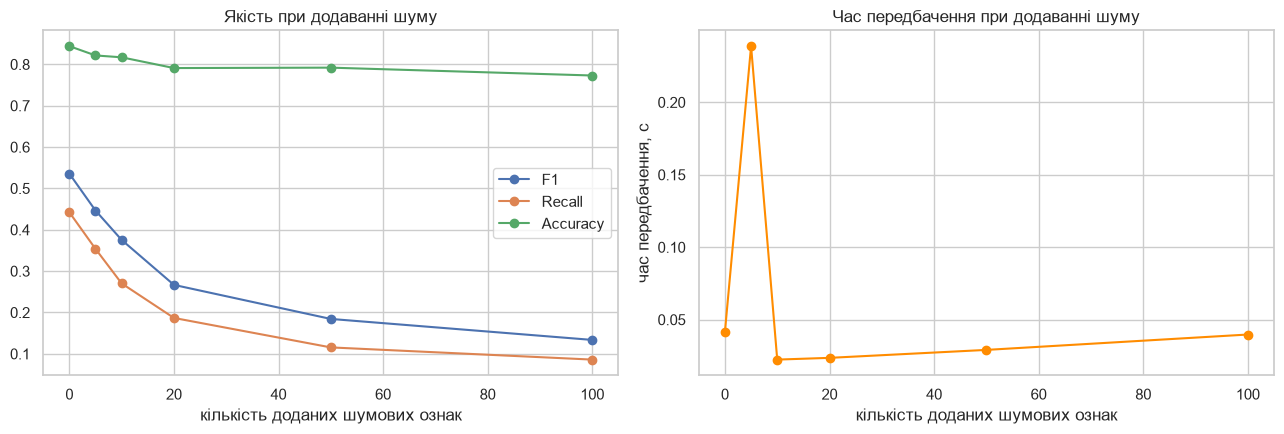

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(noise_res.index, noise_res["F1"], marker="o", label="F1")
ax[0].plot(noise_res.index, noise_res["Recall"], marker="o", label="Recall")
ax[0].plot(noise_res.index, noise_res["Accuracy"], marker="o", label="Accuracy")
ax[0].set_xlabel("кількість доданих шумових ознак")
ax[0].set_title("Якість при додаванні шуму")
ax[0].legend()

ax[1].plot(noise_res.index, noise_res["predict_time_s"], marker="o", color="darkorange")
ax[1].set_xlabel("кількість доданих шумових ознак")
ax[1].set_ylabel("час передбачення, с")
ax[1].set_title("Час передбачення при додаванні шуму")
plt.tight_layout()
plt.show()

Тепер міряємо як час передбачення залежить від розміру тестової вибірки. Беремо першими n рядків з test і замірюємо predict для моделей на всіх ознаках і на трьох найкращих. Додатково порівнюємо способи пошуку сусідів з лекції: brute force, KD-tree і Ball-tree.

,"усі ознаки, с","три ознаки, с"
розмір test,,
100,0.00451,0.00181
250,0.00665,0.00246
500,0.01132,0.00319
1000,0.02117,0.00507
2000,0.04104,0.00909


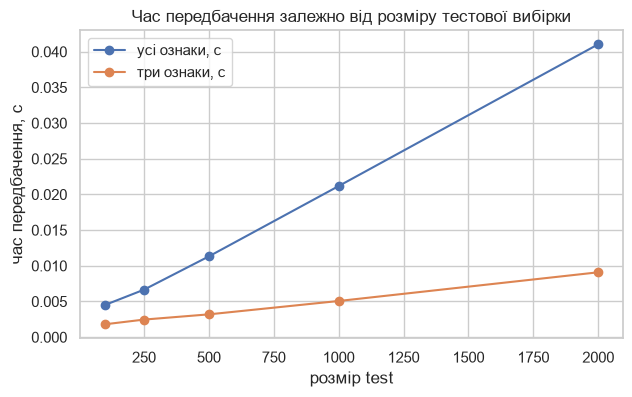

In [15]:
sizes = [100, 250, 500, 1000, len(X_test)]

model_full = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean").fit(X_train, y_train)
model_top3 = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean").fit(X_train[top3], y_train)

time_rows = []
for n in sizes:
    time_rows.append({
        "розмір test": n,
        "усі ознаки, с": time_predict(model_full, X_test.iloc[:n]),
        "три ознаки, с": time_predict(model_top3, X_test[top3].iloc[:n]),
    })
time_sizes = pd.DataFrame(time_rows).set_index("розмір test")
display(time_sizes.round(5))

time_sizes.plot(marker="o", figsize=(7, 4))
plt.ylabel("час передбачення, с")
plt.title("Час передбачення залежно від розміру тестової вибірки")
plt.show()

In [16]:
algo_rows = []
for algo in ["brute", "kd_tree", "ball_tree"]:
    start = time.perf_counter()
    model = KNeighborsClassifier(n_neighbors=best_k, algorithm=algo).fit(X_train, y_train)
    fit_t = time.perf_counter() - start
    algo_rows.append({"algorithm": algo, "fit_s": fit_t, "predict_s": time_predict(model, X_test)})

display(pd.DataFrame(algo_rows).set_index("algorithm").round(5))

,fit_s,predict_s
algorithm,,
brute,0.00246,0.02116
kd_tree,0.02085,0.04166
ball_tree,0.01018,0.10280


## Висновки

Спочатку запустили базовий k-NN, k=5, евклідова відстань отримали accuracy 0.84, але дивитися на неї немає сенсу, бо класи незбалансовані якби ми всім підряд ставили клас 0, accuracy і так була б майже 0.8 тому орієнтувалися суто на recall та F1 а він вийшов 0.5357. Коли підбирали k через крос-валідацію, найкращий F1 знов показав k=5 якщо брати k=1, модель тупо запамятовує трейн accuracy там 1.0, а на валідації падає до 0.79 - типове перенавчання, а якби обирали k по accuracy, вилізло б k=21, бо модель просто починає тупо голосувати за нульовий клас через дисбаланс. Спробували різні метрики - найкраще зайшла метрика Мінковського p=3 з вагами від відстані F1 = 0.5382 але різниця між найгіршим і найкращим варіантом мізерна близько 0.015, тому вибір метрики на цих даних погоди не робить. Зважений k-NN теж дав майже ті самі результати

Далі залишили лише 3 найкращі фічі Age, Geography_Germany, IsActiveMember. Швидкість передбачення виросла, але якість сильно просіла F1 впав до 0.35, а от коли заради тесту закинули 100 рандомних шумових фічей, модель взагалі посипалась F1 впав до 0.13. Це  показує шо зайве сміття розмиває відстані, і алгоритм вже не бачить, хто там реально найближчий сусід. Швидкість роботи очікувано падає зі збільшенням тестової вибірки для 100 об'єктів рахувало ~0.003с, для 2000 - ~0.04с, бо алгоритму треба кожного разу міряти відстань до всього трейну отже k-NN - метод простий, але дуже примхливий до сміттєвих даних і без нормальної стандартизації яку робили в 2 лабі він би тут не спрацював

## Відповіді на контрольні питання



1. Кроки алгоритму k-NN. Спочатку рахуємо відстань від нового об'єкта до кожного об'єкта з навчальної вибірки. Потім вибираємо k об'єктів із найменшою відстанню, це і є найближчі сусіди. Після цього клас нового об'єкта визначаємо голосуванням більшості серед цих k сусідів.
2. Евклідова відстань це корінь із суми квадратів різниць по всіх ознаках, а манхеттенська це сума модулів цих різниць. Наприклад для точок два три і п'ять сім евклідова відстань дорівнює п'яти, а манхеттенська семи.
3. Оптимальним за F1 у крос-валідації вийшло k = 5. При дуже малому k модель перенавчається, бо реагує на кожну точку і шум, при k=1 різниця між train і крос-валідацією була 0.2080. При дуже великому k модель недонавчається і майже завжди голосує за більший клас. Тому брали значення, де F1 для класу 1 найвищий.
4. У класичному k-NN всі k сусідів мають однаковий голос. У зваженому голос сусіда дорівнює одиниці поділеній на відстань до нього, тож ближчі сусіди впливають сильніше, а далекі майже не впливають. Через це зважений варіант менш чутливий до вибору k.
5. Стандартизація потрібна, бо k-NN рахує відстань. Без неї ознаки з великими числами, наприклад Balance і EstimatedSalary, повністю домінують над Age чи бінарними ознаками, і менші ознаки практично не впливають на сусідів.
6. Після додавання 100 шумових ознак F1 впав з 0.5357 до 0.1336, тож зайві ознаки реально погіршують модель. Тому відбір ознак із лабораторної 2 був потрібен.
7. k-NN називають лінивим, бо в ньому немає окремого етапу навчання. Метод просто запам'ятовує навчальну вибірку, а всі обчислення відбуваються під час передбачення, коли для нового об'єкта шукаються сусіди.